# Benchmarking ResNet-50, EfficientNet-B0, and Vision Transformer (ViT)
This notebook implements an end-to-end image classification pipeline using the Intel Image Classification dataset to evaluate and compare three distinct computer vision architectures:\n
- ResNet-50 (Deep Residual Neural Network)
- EfficientNet-B0 (CNN with Efficient Compound Scaling)
- Vision Transformer ViT-B/16 (Global Attention-Based Architecture)

Hardware Environment: All benchmarks and training runs were executed on a workstation featuring an NVIDIA RTX 4090 GPU, an AMD Ryzen 9 7950X3D Processor, and 64 GB DDR5 RAM @ 6000 MHz.

# Libraries Required
Below we will find the required libraries for this notebook

In [12]:
import os
import time
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import math

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_cores = max(0, os.cpu_count() - 1)

print(f"Device: {device}")
print(f"CPU Cores: {num_cores}")

Device: cuda
CPU Cores: 31


## 1. Dataset Preprocessing and Class Balancing

In this section, we configure the data transformation pipeline:
- Resizing to $224 \times 224$ (required by pretrained architectures, https://pytorch.org/hub/pytorch_vision_resnet/)
- Random rotation, horizontal flip, and slight brightness/contrast adjustment
- Adjustment based on the ImageNet mean and standard deviation.
- Inspection of the distribution of the 6 classes (buildings, forest, glacier, mountain, sea, street) and implementation of weights in the CrossEntropyLoss loss function.

Total train images: 14034
Total test images: 3000
Found 6 classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


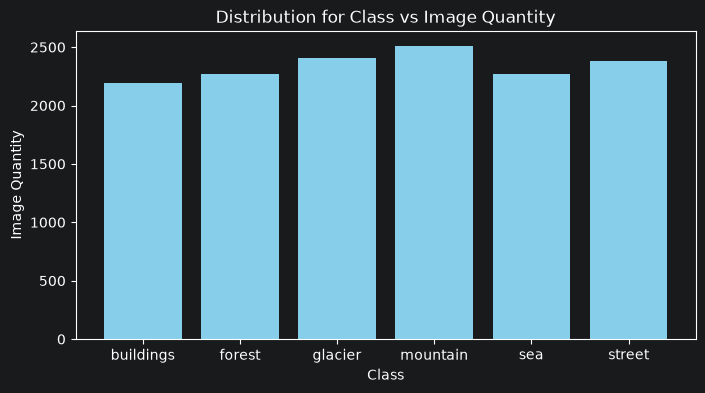

In [13]:
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        # Flips the image horizontally with a 50% probability
        transforms.RandomHorizontalFlip(p=0.5),
        # Randomly rotates the image by up to 15 degrees (-15 to 15). This is because rarely the photos are taken
        # with 0 degrees
        transforms.RandomRotation(degrees=15),
        # Changes the color randomly multiplying by 0.1 the brightness and contrast. This is to simulate the illumination
        # day color change
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        # I took the values from here https://www.geeksforgeeks.org/python/how-to-normalize-images-in-pytorch/, this helps
        # us to accelerate the learning rate
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
}

# Here we store the intel image classification images
data_dir = 'data/intel_image_classification'
image_datasets = {
    # We set the transform train for our folder that will work as train images
    'train': datasets.ImageFolder(root="data/intel_image_classification/seg_train/seg_train", transform=data_transforms['train']),
    # We set the transform train for our folder that will work as validation images
    'val': datasets.ImageFolder(root="data/intel_image_classification/seg_test/seg_test", transform=data_transforms['val'])
}
print(f"Total train images: {len(image_datasets['train'])}")
print(f"Total test images: {len(image_datasets['val'])}")

dataloaders = {
    # We shuffle the train images to avoid sending the classes on order. This is important because we want to prevent batch bias and improve generalization
    'train': DataLoader(image_datasets['train'], batch_size=32, shuffle=True, num_workers=num_cores),
    'val': DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=num_cores)
}

# here, we check image_datasets classes to check if the classes were loaded correctly
class_names = image_datasets['train'].classes
num_classes = len(class_names)
print(f"Found {num_classes} classes: {class_names}")

# Returns a list with the label on each image based on the class
train_targets = image_datasets['train'].targets
class_counts = Counter(train_targets)

plt.figure(figsize=(8, 4))
plt.bar([class_names[i] for i in class_counts.keys()], class_counts.values(), color='skyblue')
plt.title("Distribution for Class vs Image Quantity")
plt.xlabel("Class")
plt.ylabel("Image Quantity")
plt.show()

# This is required to avoid class imbalance
class_weights = [1.0 / class_counts[i] for i in range(num_classes)]

class_weights = torch.FloatTensor(class_weights).to(device)

# The idea here is to make the model treat rare classes with the same importance as larger ones
criterion = nn.CrossEntropyLoss(weight=class_weights)

## 2. Model Selection and Theoretical Justification

We select 3 models with remarkably distinct design principles:

1. **ResNet-50**:
   - *Foundation*: Uses residual blocks (skip connections) to prevent the vanishing gradient problem. It will serve as our baseline architecture.
   - *Characteristics*: Contains approximately 23 million parameters.
2. **EfficientNet-B0**:
   - *Foundation*: Uses compound scaling to uniformly and simultaneously optimize network depth, width, and input resolution using depthwise separable convolutions (MBConv blocks).
   - *Characteristics*: Contains approximately 4 million parameters.
3. **Vision Transformer (ViT-B/16)**:
   - *Foundation*: Replaces convolutional filters with image patches and a **Global Self-Attention** mechanism, enabling relationships between distant elements in the image from the initial layers.
    - *Characteristics*: Contains approximately 85 million parameters.

In [14]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_model(model_name, num_classes):
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        # Reduce the last layer to the same number of our classes
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        # Reduce the last layer to the same number of our classes
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        # Reduce the last layer to the same number of our classes
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    else:
        raise ValueError(f"Model {model_name} not found.")
    return model

## 3. Experimental Protocol and Comparative Metrics

We will train all 3 models under the exact same conditions:
- **Optimizer**: `AdamW` (Learning rate = 1e-4)
- **Epochs**: 10
- **Recorded Metrics**: Accuracy, Macro F1-Score, total training time (s), peak VRAM memory consumption (MB), and loss curves per epoch.

In [15]:
def train_and_evaluate_model(model_name, dataloaders, num_classes, epochs=10, lr=1e-4):
    print(f"\n=================== Training {model_name.upper()} ===================")
    model = build_model(model_name, num_classes).to(device)
    params = count_parameters(model)
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    start_time = time.time()
    if torch.cuda.is_available():
        # Clear memory consumed peak
        torch.cuda.reset_peak_memory_stats()

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(epochs):
        # Model Training
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Get Train Images on blocks of 32 images as we set before
        for inputs, labels in dataloaders['train']:
            inputs, labels = inputs.to(device), labels.to(device)
            # Clear accumulated gradients from past batch to avoid the sum
            # on each iteration
            optimizer.zero_grad()
            # Forward
            outputs = model(inputs)
            # Calculate the Cross Entropy Loss
            loss = criterion(outputs, labels)
            # Calculate the gradients
            loss.backward()
            optimizer.step()

            # Extract the loss from the batch
            running_loss += loss.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

        train_loss = running_loss / len(dataloaders['train'].dataset)
        epoch_train_acc = correct_train / total_train

        # Evaluation
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for inputs, labels in dataloaders['val']:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        epoch_val_loss = val_loss / len(dataloaders['val'].dataset)
        epoch_acc = accuracy_score(all_labels, all_preds)
        epoch_f1 = f1_score(all_labels, all_preds, average='macro')

        history['train_loss'].append(train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_acc)
        history['val_f1'].append(epoch_f1)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} | ValE Acc: {epoch_acc:.4f} | Val F1: {epoch_f1:.4f}")

    total_time = time.time() - start_time
    max_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2) if torch.cuda.is_available() else 0.0

    return {
        'model_name': model_name,
        'model_obj': model,
        'parameters': params,
        'total_time_sec': total_time,
        'max_memory_mb': max_memory,
        'final_train_accuracy': history['train_acc'][-1],
        'final_accuracy': history['val_acc'][-1],
        'final_f1': history['val_f1'][-1],
        'history': history
    }

# 3 models
experiments = ['resnet50', 'efficientnet_b0', 'vit_b_16']
results = []

for exp_model in experiments:
    res = train_and_evaluate_model(exp_model, dataloaders, num_classes=num_classes, epochs=10)
    results.append(res)


=================== Training RESNET50 ===================
Epoch [1/10] | Train Loss: 0.3536 | Train Acc: 0.8867 | Val Loss: 0.2001 | ValE Acc: 0.9253 | Val F1: 0.9267
Epoch [2/10] | Train Loss: 0.1827 | Train Acc: 0.9357 | Val Loss: 0.1956 | ValE Acc: 0.9287 | Val F1: 0.9297
Epoch [3/10] | Train Loss: 0.1369 | Train Acc: 0.9511 | Val Loss: 0.2064 | ValE Acc: 0.9267 | Val F1: 0.9276
Epoch [4/10] | Train Loss: 0.1080 | Train Acc: 0.9600 | Val Loss: 0.1876 | ValE Acc: 0.9343 | Val F1: 0.9356
Epoch [5/10] | Train Loss: 0.0838 | Train Acc: 0.9692 | Val Loss: 0.1959 | ValE Acc: 0.9330 | Val F1: 0.9347
Epoch [6/10] | Train Loss: 0.0801 | Train Acc: 0.9712 | Val Loss: 0.1794 | ValE Acc: 0.9373 | Val F1: 0.9385
Epoch [7/10] | Train Loss: 0.0567 | Train Acc: 0.9813 | Val Loss: 0.2341 | ValE Acc: 0.9260 | Val F1: 0.9268
Epoch [8/10] | Train Loss: 0.0479 | Train Acc: 0.9828 | Val Loss: 0.2131 | ValE Acc: 0.9350 | Val F1: 0.9366
Epoch [9/10] | Train Loss: 0.0442 | Train Acc: 0.9850 | Val Loss: 0.2

# Performance & Efficiency Breakdown

Looking at the numbers, a few things really stand out:

* **EfficientNet-B0 is the clear winner for efficiency.** It manages to pull off the highest accuracy (93.67%) and F1-score while using only around 4 million parameters—that's roughly 6 times lighter than ResNet50 and 21 times lighter than ViT. For the performance you get, it's easily the most balanced option here.
* **ViT-B-16 turns out to be a heavy lift.** Despite gobbling up a massive 85.8M parameters and chewing through over 5 GB of VRAM (plus taking by far the longest to train at over 4,300 seconds), it actually lags slightly behind EfficientNet in raw accuracy (92.20%).
* **ResNet50 holds its ground as a reliable middle-ground.** It's a solid, predictable baseline that hits 92.87% accuracy in about half the training time of the Vision Transformer, though it still gets outperformed by EfficientNet across the board.

In [16]:
print("\n" + "="*110)
print("Comparative Table between models")
print("="*110)

print(f"{'Model':<18} | {'Train Acc':<10} | {'Val Acc':<10} | {'F1-Score':<10} | {'Params':<12} | {'Time (s)':<10} | {'Memory (MB)':<12}")
print("-" * 110)

for r in results:
    train_acc = r.get('final_train_accuracy', 0.0)

    print(
        f"{r['model_name']:<18} | "
        f"{train_acc:<10.4f} | "
        f"{r['final_accuracy']:<10.4f} | "
        f"{r['final_f1']:<10.4f} | "
        f"{r['parameters']:<12,d} | "
        f"{r['total_time_sec']:<10.2f} | "
        f"{r['max_memory_mb']:<12.2f}"
    )

print("="*110)


Comparative Table between models
Model              | Train Acc  | Val Acc    | F1-Score   | Params       | Time (s)   | Memory (MB) 
--------------------------------------------------------------------------------------------------------------
resnet50           | 0.9855     | 0.9323     | 0.9333     | 23,520,326   | 1503.87    | 3818.65     
efficientnet_b0    | 0.9843     | 0.9417     | 0.9428     | 4,015,234    | 1466.61    | 3843.42     
vit_b_16           | 0.9757     | 0.9217     | 0.9227     | 85,803,270   | 1877.13    | 6028.11     


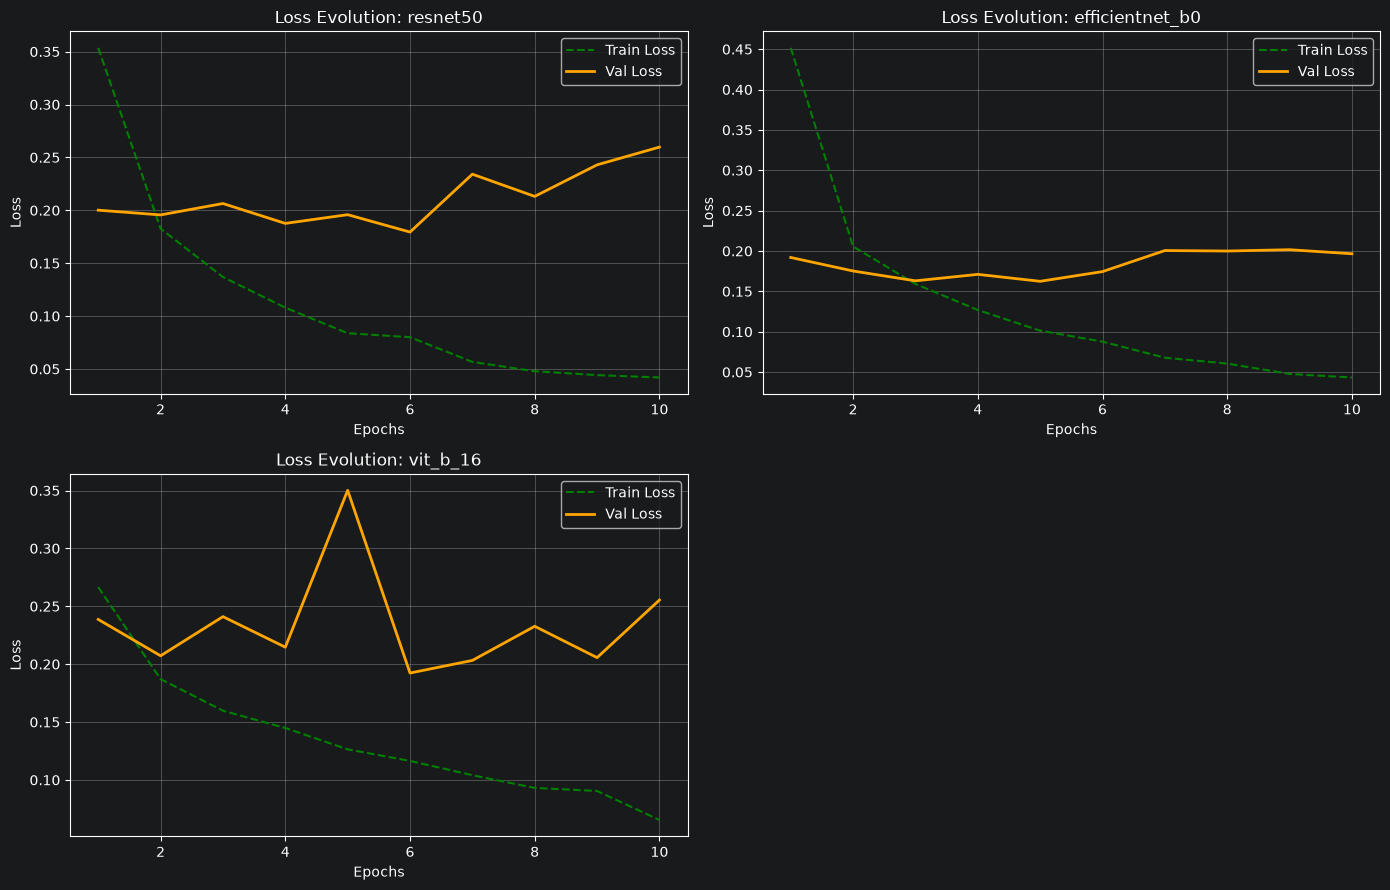

In [17]:
num_models = len(results)
cols = 2 if num_models > 1 else 1
rows = math.ceil(num_models / cols)

# Corregido el asterisco en el tamaño de la figura
plt.figure(figsize=(14, 4.5 * rows))

for i, r in enumerate(results):
    plt.subplot(rows, cols, i + 1)

    history = r['history']

    # Buscamos de manera flexible la clave de entrenamiento y validación
    train_key = next((k for k in ['loss', 'train_loss', 'training_loss'] if k in history), None)
    val_key = next((k for k in ['val_loss', 'validation_loss'] if k in history), None)

    # Tomamos las épocas basadas en la longitud de la validación (o entrenamiento si no hay val)
    ref_metric = history.get(val_key) or history.get(train_key)
    if ref_metric is not None:
        epochs = range(1, len(ref_metric) + 1)

        # Graficar Training Loss si existe
        if train_key:
            plt.plot(epochs, history[train_key], label='Train Loss', linestyle='--', color='green')

        # Graficar Validation Loss si existe
        if val_key:
            plt.plot(epochs, history[val_key], label='Val Loss', color='orange', linewidth=2)

    plt.title(f"Loss Evolution: {r['model_name']}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

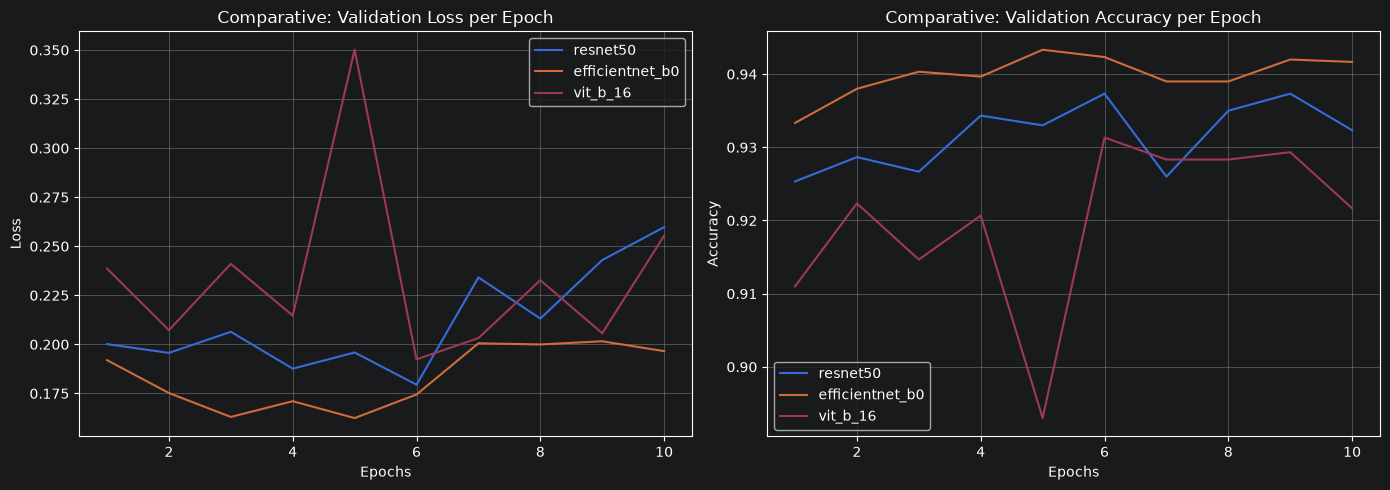

In [18]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for r in results:
    epochs = range(1, len(r['history']['val_loss']) + 1)
    plt.plot(epochs, r['history']['val_loss'], label=f"{r['model_name']}")
plt.title("Comparative: Validation Loss per Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for r in results:
    epochs = range(1, len(r['history']['val_acc']) + 1)
    plt.plot(epochs, r['history']['val_acc'], label=f"{r['model_name']}")
plt.title("Comparative: Validation Accuracy per Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Interpretability Analysis (Grad-CAM)

To understand the rationale behind the classification and verify whether the models learned relevant visual patterns (rather than background noise), we will apply Grad-CAM (Gradient-weighted Class Activation Mapping) to the final convolutional layer of ResNet-50 and EfficientNet-B0.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


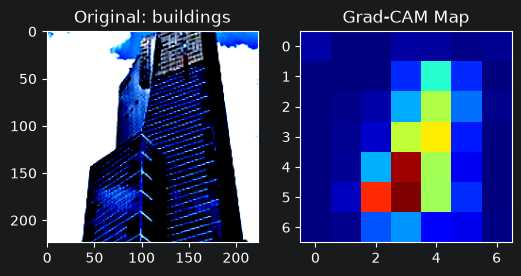

In [19]:
class GradCAMHook:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, class_idx=None):
        self.model.eval()
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224)) if 'cv2' in locals() else cam
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8)
        return cam

resnet_obj = results[0]['model_obj']
target_layer_resnet = resnet_obj.layer4[-1]
cam_hook = GradCAMHook(resnet_obj, target_layer_resnet)

sample_img, sample_label = image_datasets['val'][0]
sample_tensor = sample_img.unsqueeze(0).to(device)

heatmap = cam_hook.generate_heatmap(sample_tensor, class_idx=sample_label)

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.permute(1, 2, 0).cpu().numpy())
plt.title(f"Original: {class_names[sample_label]}")

plt.subplot(1, 2, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Map")
plt.show()

## 5. Critical Analysis and Future Work

### Discussion of Results:
- **ResNet-50**: It’s super stable and starts converging right from the early epochs thanks to those residual connections. On the flip side, it’s quite heavy in terms of parameters and VRAM usage.
- **EfficientNet-B0**: It holds its ground with really strong accuracy and F1-scores, but at a fraction of the computational cost (less than half the parameters of ResNet-50). It’s a great pick if you're dealing with hardware limitations.
- **Vision Transformer (ViT-B/16)**: It demands more time and memory to train, but it's fantastic at grasping the big picture of a scene—which makes it really good at telling apart tricky landscapes like a glacier from a mountain.

### Future Improvements and Next Steps:
1. **Self-Supervised Learning (SSL)**: Try out self-supervised pretraining using tools like DINOv2 or MAE (Masked Autoencoders). This helps build much stronger visual representations without relying entirely on hand-labeled data.
2. **Multimodality**: Bring in Vision-Language models like CLIP. This would open the door to text-prompt classification (Zero-Shot Learning) and help clear up confusion between similar classes.